<a href="https://colab.research.google.com/github/4LParis/Praktikum-Machine-Learning/blob/main/P9_ML_AlFaridzi_229_R7C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

In [2]:
data = load_breast_cancer(as_frame=True)

X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [3]:
# SVM sangat sensitif terhadap skala fitur,
# scaling WAJIB dilakukan

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

In [4]:
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1],
    "svm__kernel": ["rbf", "linear"]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Parameter terbaik:", grid_search.best_params_)
print("F1-Score terbaik (CV):",
      round(grid_search.best_score_, 3))

Parameter terbaik: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
F1-Score terbaik (CV): 0.984


In [5]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Akurasi Test:",
      round(accuracy_score(y_test, y_pred), 3))

print(classification_report(y_test, y_pred))

Akurasi Test: 0.982
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



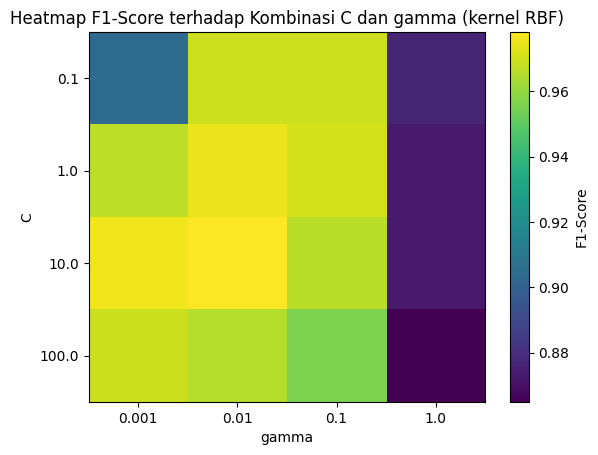

In [6]:
import pandas as pd

hasil = pd.DataFrame(grid_search.cv_results_)

pivot = hasil.pivot_table(
    values="mean_test_score",
    index="param_svm__C",
    columns="param_svm__gamma"
)

plt.imshow(pivot, cmap="viridis", aspect="auto")

plt.xticks(
    range(len(pivot.columns)),
    pivot.columns
)

plt.yticks(
    range(len(pivot.index)),
    pivot.index
)

plt.xlabel("gamma")
plt.ylabel("C")

plt.title("Heatmap F1-Score terhadap Kombinasi C dan gamma (kernel RBF)")

plt.colorbar(label="F1-Score")

plt.show()

In [7]:
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=kernel))
    ])

    model.fit(X_train, y_train)

    acc = accuracy_score(y_test, model.predict(X_test))

    print(f"Kernel {kernel}: akurasi = {acc:.3f}")

Kernel linear: akurasi = 0.974
Kernel poly: akurasi = 0.912
Kernel rbf: akurasi = 0.982


In [8]:
fitur = ["mean radius", "mean texture"]
X2 = X[fitur].values
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)

configs = [  # (kernel, C, gamma)
    ("linear", 1, "scale"),
    ("poly", 1, "scale"),
    ("rbf", 1, 0.01),
    ("rbf", 1, 1),
    ("rbf", 100, 0.01),
    ("rbf", 100, 1),
]

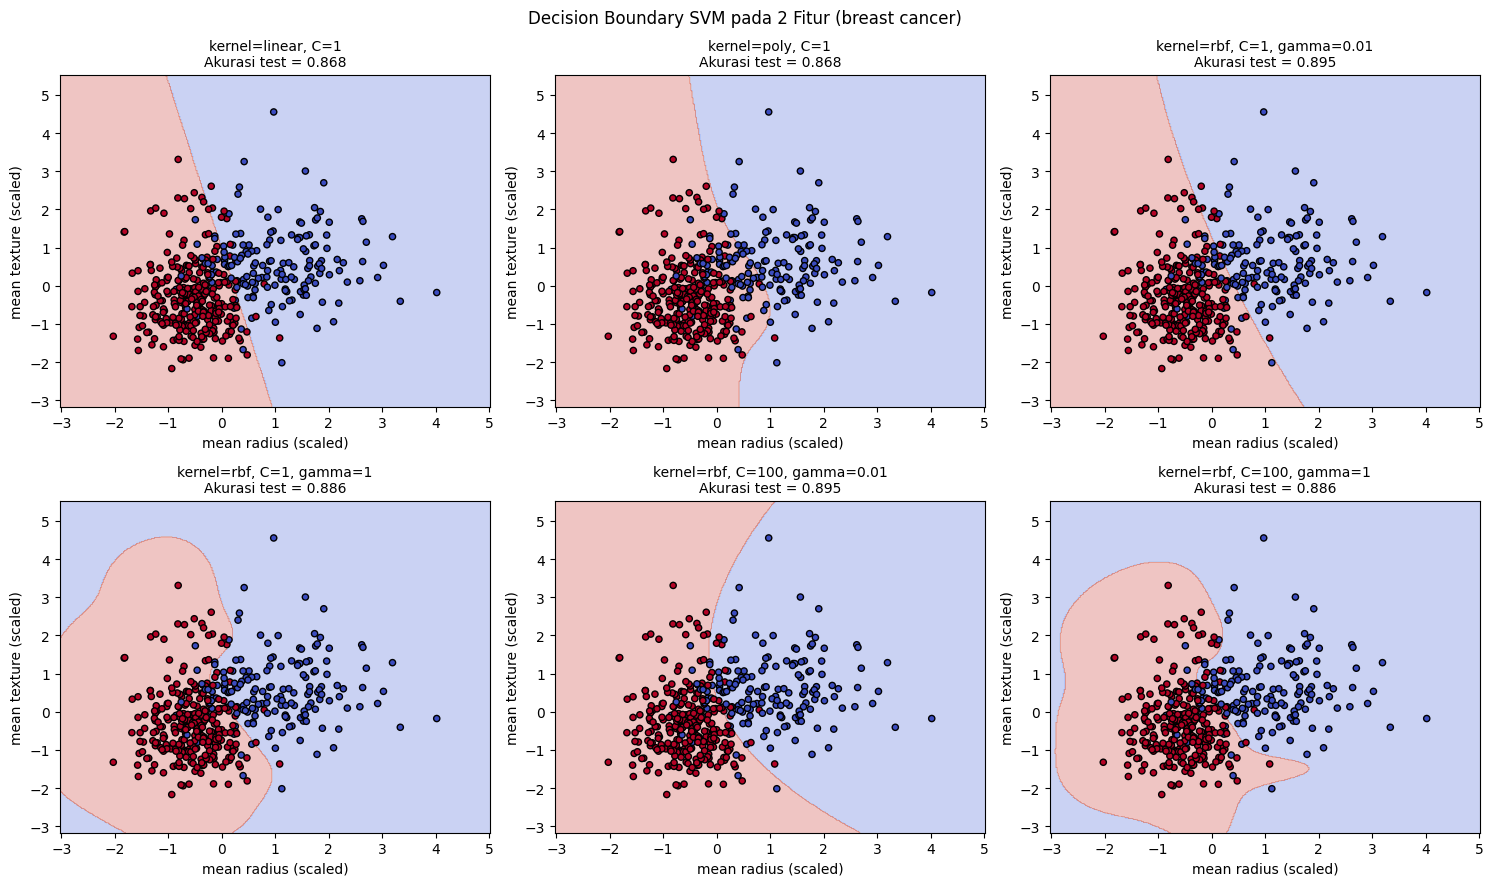

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Scale the 2D features (required since SVM is scale-sensitive)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X2_train)
X_test_s = scaler.transform(X2_test)

# 2. Convert configs tuples into dicts to support unpacking (e.g. SVC(**cfg))
konfigurasi = []
for kernel, C, gamma in configs:
    cfg = {"kernel": kernel, "C": C}
    if kernel == "rbf":
        cfg["gamma"] = gamma
    konfigurasi.append(cfg)

# 3. Create a meshgrid to plot decision boundaries
x_min, x_max = X_train_s[:, 0].min() - 1, X_train_s[:, 0].max() + 1
y_min, y_max = X_train_s[:, 1].min() - 1, X_train_s[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# 4. Plot the decision boundaries
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, cfg in zip(axes.ravel(), konfigurasi):
    model = SVC(**cfg)
    model.fit(X_train_s, y_train)
    acc = model.score(X_test_s, y_test)

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_s[:, 0], X_train_s[:, 1], c=y_train,
               cmap="coolwarm", edgecolors="k", s=20)
    judul = ", ".join(f"{k}={v}" for k, v in cfg.items())
    ax.set_title(f"{judul}\nAkurasi test = {acc:.3f}", fontsize=10)
    ax.set_xlabel(fitur[0] + " (scaled)")
    ax.set_ylabel(fitur[1] + " (scaled)")

plt.suptitle("Decision Boundary SVM pada 2 Fitur (breast cancer)")
plt.tight_layout()
plt.show()